# 01: Exploratory data analysis
Hotel customer feedback in two languages, both rated 1–5 stars:
- **Arabic:** HARD (Booking.com, 2016). 409k reviews; a stratified 20k sample is used.
- **English:** TripAdvisor hotel reviews. 20,491 reviews.

Labels: 1–2 stars → negative, 3 → neutral, 4–5 → positive (same rule for both languages).

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src.config import FIGURES, LABELS
from src.data import load_arabic, load_english
from src.clean import strip_booking_score_title
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 160)
df = pd.read_parquet("../data/processed/reviews.parquet")
df.groupby("lang").size()

lang
ar    20000
en    20491
dtype: int64

## 1. Label leakage in the Arabic data (the most important finding)

In [2]:
ar_raw = pd.read_csv("../data/raw/hard_unbalanced_reviews.txt", sep="\t", encoding="utf-16", quoting=3)
r = ar_raw["review"].astype(str)
unquoted = ~r.str.startswith("“")
first = r[unquoted].str.split(". ", n=1, regex=False).str[0].str.lstrip('"')
top = first.value_counts().head(11).index
leak = pd.crosstab(first[first.isin(top)], ar_raw.loc[unquoted, "rating"][first.isin(top)])
print(f"Reviews starting with an auto-generated score word: {first.isin(top).mean() * unquoted.mean():.1%} of all Arabic reviews")
leak

Reviews starting with an auto-generated score word: 43.6% of all Arabic reviews


rating,1,2,3,4,5
review,,,,,
استثنائي,0,0,0,0,40031
جيد,0,0,0,37234,0
جيد جداً,0,0,0,12751,0
حسن,0,0,7354,0,0
رائع,0,0,0,12682,0
ضعيف,0,6360,0,0,0
ضعيف جداً,5168,0,0,0,0
مخيب للأمل,0,9521,0,0,0
مرضي,0,0,18371,0,0


These 11 words open **44%** of all Arabic reviews, and each maps to **exactly one** star rating (e.g. استثنائي "exceptional" → always 5, مرضي "satisfactory" → always 3).
Booking.com writes them in when a guest leaves no title. A model would learn "word → label" and look close to perfect
on almost half the Arabic data while learning nothing about sentiment. `strip_booking_score_title` removes the word.
User-written titles are in “…” quotes and are kept: those are the guest's own words.

In [3]:
examples = ar_raw.loc[unquoted, ["rating", "review"]].sample(4, random_state=0)
examples.assign(after_strip=examples["review"].map(strip_booking_score_title))

,rating,review,after_strip
54957,5,استثنائي. كل شيئ وممتاز للعوائل. لاشي,كل شيئ وممتاز للعوائل. لاشي
313466,5,"""“تجربة رائعة ، وسوف تتكرر ان شاء الله في رمادا بلازا عند زيارتي القادمة الى دبي”. الافطار ممتاز لذيذ ومنوع ، طاقم العمل بشوشين ومتجاوبين ، الموقع رائع وعلى...","""“تجربة رائعة ، وسوف تتكرر ان شاء الله في رمادا بلازا عند زيارتي القادمة الى دبي”. الافطار ممتاز لذيذ ومنوع ، طاقم العمل بشوشين ومتجاوبين ، الموقع رائع وعلى..."
139175,4,جيد. الفندق جميل وهادئ افضل من بعض الفنادق الخمس نجوم. الموقع غير واضح,الفندق جميل وهادئ افضل من بعض الفنادق الخمس نجوم. الموقع غير واضح
331779,3,مرضي. قربه من الحرررم. الاسرة كلها منفصلةالدخول الساعة 4 عصرا وعدم مراعاة غير ذلك,قربه من الحرررم. الاسرة كلها منفصلةالدخول الساعة 4 عصرا وعدم مراعاة غير ذلك


## 2. Class balance per language

label,negative,neutral,positive
lang,,,
ar,13.1,19.9,67.1
en,15.7,10.7,73.7


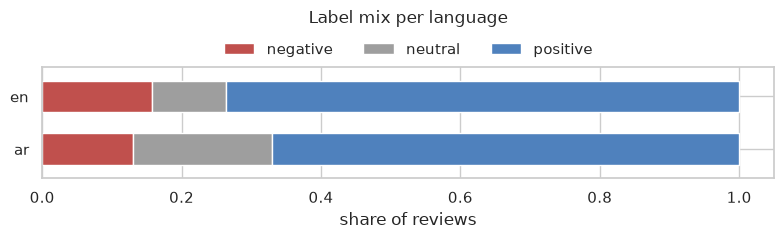

In [4]:
dist = pd.crosstab(df["lang"], df["label"], normalize="index").reindex(columns=LABELS)
display((dist * 100).round(1))
ax = dist.plot(kind="barh", stacked=True, figsize=(8, 2.6), color=["#c0504d", "#9e9e9e", "#4f81bd"], width=0.6)
ax.set_xlabel("share of reviews"); ax.set_ylabel(""); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.35), frameon=False)
ax.set_title("Label mix per language", pad=32)
plt.tight_layout(); plt.savefig(FIGURES / "eda_label_mix.png", dpi=150); plt.show()

Positive is about 70% in both languages, and **neutral is the smallest class in English (11%)**. Accuracy would reward
a model that says "positive" every time, so the primary metric is **macro-F1**, which weighs the three classes equally.

## 3. Review length

label,negative,neutral,positive
lang,,,
ar,19.0,17.0,14.0
en,90.0,86.0,73.0


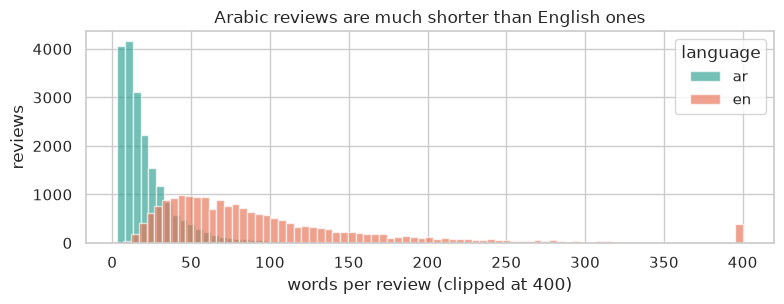

In [5]:
df["n_words"] = df["text"].str.split().str.len()
display(df.groupby(["lang", "label"])["n_words"].median().unstack().reindex(columns=LABELS))
fig, ax = plt.subplots(figsize=(8, 3.2))
for lang, c in (("ar", "#2a9d8f"), ("en", "#e76f51")):
    ax.hist(df.loc[df.lang == lang, "n_words"].clip(upper=400), bins=80, alpha=.65, label=lang, color=c)
ax.set_xlabel("words per review (clipped at 400)"); ax.set_ylabel("reviews"); ax.legend(title="language")
ax.set_title("Arabic reviews are much shorter than English ones")
plt.tight_layout(); plt.savefig(FIGURES / "eda_length.png", dpi=150); plt.show()

Median length is 14–19 words for Arabic and 73–90 for English, depending on the class. Short Arabic reviews carry less signal, and many are
"liked: X. disliked: Y" fragments (Booking's two-box form), which is one reason Arabic is the harder half.

## 4. Label noise: does the text agree with the stars?

In [6]:
ar = df[df.lang == "ar"]
for label in LABELS:
    print(f"--- {label} (Arabic) ---")
    for t in ar[ar.label == label]["text"].sample(4, random_state=7): print("  ", t[:150])

--- negative (Arabic) ---
   "لن اذهب الى هذا الفندق ابداً". لم انم الى الصباح بسبب اصوات مجهولة المصدر و صوت البحر انصح الذين يحجزون ان يختاور مطلة على المدينة وليس البحر. اصوات 
   "المستوى ضعيف". هدوء المكان وموقعه. ريحة غير مقبوله في مدخل الفندق والمصعد والممراتالمظهر العام للفندق قديم ويحتاج الى تغيير ووجود بعض الاغراض وحاجيات
   لا شي. فيه تغيير بالسعر عن الوصول حجزت ٤٠٠ وآخر شي اكتشف سعر الغرفة ٦٣١
   "المصدقية لا توجد". تقريباً الموقع. التأخير بتسليم الغرفاسلوب العاملين في المطعمالنظافة أقدمية الأثاث على ينهم يقولون انه جديد
--- neutral (Arabic) ---
   "اسوى ليلة اسكن فيها فندق ذات الخمسة نجوم". . الحمام بدون معجون أسنان ولا فرشاة تم طلب ولم احصل عليها ايضا تم تسليمي غرفة لذوي الاحتياجات الخاصة
   الموقع بعيد جدا جدا
   "غرفتين بسرير كبير وسرير صغير غير كافي لزوجين مع ٣اطفال كما هو العرض في بوكنق". الموقع جميل. المواقف في مبنى مجاور وبعيدة
   "رحلة دبي". التعامل من طاقم الفندق. أسعاره غاليه ولايستحق 4 نجوم
--- positive (Arabic) ---
   شقق فندقية التأثيث، ونظيفة جداً، وموقعها من

In [7]:
en = df[df.lang == "en"]
for label in LABELS:
    print(f"--- {label} (English) ---")
    for t in en[en.label == label]["text"].sample(3, random_state=7): print("  ", t[:200])

--- negative (English) ---
   impresion desk worst november 8 2008 arrived condado plaza 6:15pm, friend began check-in process niece soprano needed stay quiet place night, friend introduced desk person assisting guests moment, gen
   run over-priced recently stayed days hotel, cheaper hotels saw disappointed standards considering paid, stayed star hotel france week cheaper higher quality, walls room filthy bath problems shower hos
   definitely substandard booked nights novotel benoa advice travel agent unhappy stay.problems largely attributable peak season resort fully booked, kind service not acceptable, check-in slow service as
--- neutral (English) ---
   convenient location pretty good value plus sides hotel 1 proximity beach shopping 2 size rooms, rooms large bit disappointment, decoration really need updating, bathroom horrible rubber shower curtain
   reasonable finding reasonably priced accommodation ny challenging task, quite poorly located not maintained, room renovated kurt

- **Booking's form mixes praise and complaints.** Guests fill a "liked" box and a "disliked" box, so most Arabic reviews,
  even 5-star ones, contain a complaint, and many 2-star ones contain praise.
- **The star rating isn't always the text's sentiment.** Booking's 1–5 scale here comes from its 10-point score, so a guest can
  write "ممتاز" (excellent) and land in 2 stars. These are label errors that no model can get right; they cap the achievable score.
- **The English text arrives pre-processed:** lower-cased, most punctuation and many stop words removed
  ("nice hotel expensive parking got good deal stay hotel anniversary"). That suits TF-IDF but hurts a transformer
  trained on natural sentences: a fairness caveat for the comparison.

## 5. Arabic dialect and spelling variation

In [8]:
import re
variants = {"alef forms (أ/إ/آ)": r"[أإآ]", "taa marbuta (ة)": r"ة", "alef maqsura (ى)": r"ى",
            "elongation (ـ)": r"ـ", "diacritics": r"[\u064B-\u0652]", "repeated letters (3+)": r"(.)\1\1"}
pd.Series({k: ar["text"].map(lambda t: bool(re.search(v, t))).mean() for k, v in variants.items()}).mul(100).round(1).rename("% of Arabic reviews")

alef forms (أ/إ/آ)       31.9
taa marbuta (ة)          62.9
alef maqsura (ى)         28.8
elongation (ـ)            0.3
diacritics               10.9
repeated letters (3+)     8.0
Name: % of Arabic reviews, dtype: float64

The same word is spelled several ways (فندق جميلة / جميله, أكثر / اكثر), which splits the vocabulary for a bag-of-words model.
`clean_for_tfidf` normalises these for the baseline. The transformer receives the original text, because its tokenizer was
trained on unnormalised Arabic.

## Takeaways for modelling
1. Strip the Booking score word (leakage).
2. Use macro-F1 with class weighting; neutral is the hard, small class.
3. Expect a lower ceiling on Arabic (short texts, two-box form, noisy star mapping).
4. One fixed split, stratified by language × label; every approach is scored on the same test rows.